In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats

plt.rcParams.update({'figure.dpi': 120, 'font.size': 9})

# ── Load data ─────────────────────────────────────────────────────────────────
dfs, tdfs = [], []
for d in [2, 3, 4]:
    df = pd.read_csv(f'ROUND_5/prices_round_5_day_{d}.csv', sep=';')
    df['day'] = d
    dfs.append(df)
    t = pd.read_csv(f'ROUND_5/trades_round_5_day_{d}.csv', sep=';')
    t['day'] = d
    tdfs.append(t)

prices = pd.concat(dfs, ignore_index=True)
trades = pd.concat(tdfs, ignore_index=True)

PRODUCTS = sorted(prices['product'].unique())
print(f'{len(PRODUCTS)} products, {len(prices):,} price rows, {len(trades):,} trade rows')

50 products, 1,500,000 price rows, 35,385 trade rows


## 1 — Per-Product MR + MM Stats Table
For each product across all days: AC1, Variance Ratio (lag 5), Half-Life, Avg Mid Price, Avg Spread, Volume, Vol×Spread.

In [2]:
def ac1(series):
    """Lag-1 autocorrelation of returns. Negative = mean-reverting."""
    r = series.pct_change().dropna()
    if len(r) < 20:
        return np.nan
    return r.autocorr(lag=1)

def variance_ratio(series, lag=5):
    """Variance ratio test at given lag. VR < 1 = MR, VR > 1 = trending."""
    r = series.diff().dropna()
    if len(r) < lag * 4:
        return np.nan
    var1 = r.var()
    r_lag = series.diff(lag).dropna() / lag
    vr = r_lag.var() / var1 if var1 > 0 else np.nan
    return vr

def half_life(series):
    """AR(1) half-life of mean reversion in ticks. Only meaningful if AC1 < 0."""
    r = series.pct_change().dropna().values
    if len(r) < 20:
        return np.nan
    b = np.corrcoef(r[:-1], r[1:])[0, 1]
    if b >= 0:
        return np.inf
    return -np.log(2) / np.log(1 + b)

def hurst(series, max_lag=50):
    """Hurst exponent via R/S analysis. H<0.5 MR, H>0.5 trending, H=0.5 RW."""
    s = series.dropna().values
    lags = range(4, min(max_lag, len(s)//4))
    tau = [np.std(np.subtract(s[l:], s[:-l])) for l in lags]
    if len(tau) < 3 or any(t == 0 for t in tau):
        return np.nan
    h, _, _, _, _ = stats.linregress(np.log(list(lags)), np.log(tau))
    return h

rows = []
# Volume from trades
vol_map = trades.groupby('symbol')['quantity'].sum().to_dict()

for sym in PRODUCTS:
    sub = prices[prices['product'] == sym].copy()
    sub = sub.sort_values(['day', 'timestamp'])
    mid = sub['mid_price']
    bspread = (sub['ask_price_1'] - sub['bid_price_1']).median()

    # Per-day AC1 and VR, then average (more robust)
    ac1_list, vr_list, hl_list = [], [], []
    for d in [2, 3, 4]:
        dm = sub[sub['day'] == d]['mid_price']
        if len(dm) > 20:
            ac1_list.append(ac1(dm))
            vr_list.append(variance_ratio(dm, lag=5))
            hl_list.append(half_life(dm))

    avg_ac1 = np.nanmean(ac1_list)
    avg_vr  = np.nanmean(vr_list)
    avg_hl  = np.nanmean([h for h in hl_list if np.isfinite(h)])
    h_exp   = hurst(mid)
    avg_mid = mid.mean()
    vol     = vol_map.get(sym, 0)
    vol_x_spread = vol * bspread

    rows.append({
        'product': sym,
        'avg_mid': round(avg_mid, 1),
        'spread': round(bspread, 1),
        'volume': vol,
        'vol_x_spread': round(vol_x_spread, 0),
        'ac1': round(avg_ac1, 4),
        'VR5': round(avg_vr, 4),
        'half_life': round(avg_hl, 1) if np.isfinite(avg_hl) else np.inf,
        'hurst': round(h_exp, 3) if h_exp is not np.nan else np.nan,
    })

stats_df = pd.DataFrame(rows)

# MR score: lower is more mean-reverting (AC1 most important)
stats_df['mr_score'] = stats_df['ac1'] * 0.6 + (stats_df['VR5'] - 1) * 0.4

pd.set_option('display.max_rows', 60)
pd.set_option('display.float_format', '{:.2f}'.format)
print('=== ALL PRODUCTS — sorted by AC1 (most mean-reverting first) ===')
print(stats_df.sort_values('ac1')[['product','avg_mid','spread','volume','vol_x_spread','ac1','VR5','half_life','hurst']].to_string(index=False))

/var/folders/m1/r509ltd163s9j5gyx98z2mkr0000gn/T/ipykernel_87435/743590685.py:59: RuntimeWarning: Mean of empty slice
  avg_hl  = np.nanmean([h for h in hl_list if np.isfinite(h)])
/var/folders/m1/r509ltd163s9j5gyx98z2mkr0000gn/T/ipykernel_87435/743590685.py:59: RuntimeWarning: Mean of empty slice
  avg_hl  = np.nanmean([h for h in hl_list if np.isfinite(h)])
/var/folders/m1/r509ltd163s9j5gyx98z2mkr0000gn/T/ipykernel_87435/743590685.py:59: RuntimeWarning: Mean of empty slice
  avg_hl  = np.nanmean([h for h in hl_list if np.isfinite(h)])


=== ALL PRODUCTS — sorted by AC1 (most mean-reverting first) ===
                      product  avg_mid  spread  volume  vol_x_spread   ac1  VR5  half_life  hurst
                ROBOT_IRONING  8701.60    6.00    1805      10830.00 -0.12 0.16       6.00   0.48
  OXYGEN_SHAKE_EVENING_BREATH  9271.90   12.00    1805      21660.00 -0.11 0.16       6.50   0.47
                 ROBOT_DISHES 10018.30    7.00    1805      12635.00 -0.10 0.16      92.60   0.40
       OXYGEN_SHAKE_CHOCOLATE  9556.90   12.00    1805      21660.00 -0.08 0.17      33.50   0.48
          SNACKPACK_CHOCOLATE  9843.40   17.00    1805      30685.00 -0.03 0.19      22.80   0.50
            SNACKPACK_VANILLA 10097.30   17.00    1805      30685.00 -0.03 0.19      25.80   0.51
          SNACKPACK_PISTACHIO  9495.80   16.00    1805      28880.00 -0.03 0.19      29.00   0.48
             MICROCHIP_SQUARE 13594.70   12.00    1119      13428.00 -0.02 0.19      37.20   0.49
                   PEBBLES_XS  7404.60    9.00    228

## 2 — Ranked Tables

In [3]:
print('=== RANKED BY AVERAGE MID PRICE (best MM $ per tick) ===')
print(stats_df.sort_values('avg_mid', ascending=False)[['product','avg_mid','spread','volume','vol_x_spread','ac1']].to_string(index=False))

print()
print('=== RANKED BY VOL × SPREAD (best estimated MM profit pool) ===')
print(stats_df.sort_values('vol_x_spread', ascending=False)[['product','avg_mid','spread','volume','vol_x_spread','ac1']].to_string(index=False))

print()
print('=== STRONGEST MR CANDIDATES (AC1 < -0.05) ===')
mr = stats_df[stats_df['ac1'] < -0.05].sort_values('ac1')
print(mr[['product','avg_mid','spread','volume','vol_x_spread','ac1','VR5','half_life','hurst']].to_string(index=False))

print()
print('=== STRONG TRENDING (AC1 > 0.03, Hurst > 0.5) ===')
tr = stats_df[(stats_df['ac1'] > 0.03) | (stats_df['hurst'] > 0.5)].sort_values('hurst', ascending=False)
print(tr[['product','avg_mid','spread','volume','vol_x_spread','ac1','VR5','hurst']].to_string(index=False))

=== RANKED BY AVERAGE MID PRICE (best MM $ per tick) ===
                      product  avg_mid  spread  volume  vol_x_spread   ac1
             MICROCHIP_SQUARE 13594.70   12.00    1119      13428.00 -0.02
                   PEBBLES_XL 13225.60   17.00    2283      38811.00  0.01
          OXYGEN_SHAKE_GARLIC 11925.60   15.00    1805      27075.00 -0.00
          SLEEP_POD_POLYESTER 11840.60   11.00    1805      19855.00 -0.00
             SLEEP_POD_COTTON 11527.60   10.00    1805      18050.00 -0.00
    GALAXY_SOUNDS_BLACK_HOLES 11466.90   14.00    1805      25270.00 -0.02
              SLEEP_POD_SUEDE 11397.40   10.00    1805      18050.00 -0.01
                    PANEL_2X4 11265.40   10.00    1805      18050.00 -0.00
             UV_VISOR_MAGENTA 11111.80   14.00    1805      25270.00 -0.00
                ROBOT_MOPPING 11100.20    8.00    1805      14440.00 -0.01
   GALAXY_SOUNDS_SOLAR_FLAMES 11092.60   14.00    1805      25270.00 -0.01
                 UV_VISOR_RED 11063.30   14

## 3 — Rolling AC1 Stability (is MR consistent across days?)

In [4]:
# Per-day AC1 breakdown for all products with avg AC1 < -0.04
mr_products = stats_df[stats_df['ac1'] < -0.04]['product'].tolist()

day_ac1 = {}
for sym in mr_products:
    sub = prices[prices['product'] == sym]
    day_ac1[sym] = {}
    for d in [2, 3, 4]:
        dm = sub[sub['day'] == d]['mid_price']
        day_ac1[sym][f'D{d}'] = round(ac1(dm), 3)

ac1_stability = pd.DataFrame(day_ac1).T
ac1_stability['avg'] = ac1_stability.mean(axis=1)
print('Per-day AC1 for MR candidates (stable negatives = reliable signal):')
print(ac1_stability.sort_values('avg').to_string())

Per-day AC1 for MR candidates (stable negatives = reliable signal):
                               D2    D3    D4   avg
ROBOT_IRONING               -0.16 -0.08 -0.11 -0.12
OXYGEN_SHAKE_EVENING_BREATH -0.16 -0.10 -0.08 -0.11
ROBOT_DISHES                 0.00 -0.00 -0.29 -0.10
OXYGEN_SHAKE_CHOCOLATE      -0.12 -0.01 -0.10 -0.08


## 4 — Intra-Family Pair Spreads (derived MR signals)
Check co-integration and MR for pairs within the same family.

In [5]:
from itertools import combinations

FAMILIES = {
    'PEBBLES':     ['PEBBLES_XS','PEBBLES_S','PEBBLES_M','PEBBLES_L','PEBBLES_XL'],
    'MICROCHIP':   ['MICROCHIP_CIRCLE','MICROCHIP_OVAL','MICROCHIP_RECTANGLE','MICROCHIP_SQUARE','MICROCHIP_TRIANGLE'],
    'ROBOT':       ['ROBOT_DISHES','ROBOT_IRONING','ROBOT_LAUNDRY','ROBOT_MOPPING','ROBOT_VACUUMING'],
    'SNACKPACK':   ['SNACKPACK_CHOCOLATE','SNACKPACK_PISTACHIO','SNACKPACK_RASPBERRY','SNACKPACK_STRAWBERRY','SNACKPACK_VANILLA'],
    'SLEEP_POD':   ['SLEEP_POD_COTTON','SLEEP_POD_LAMB_WOOL','SLEEP_POD_NYLON','SLEEP_POD_POLYESTER','SLEEP_POD_SUEDE'],
    'GALAXY':      ['GALAXY_SOUNDS_BLACK_HOLES','GALAXY_SOUNDS_DARK_MATTER','GALAXY_SOUNDS_PLANETARY_RINGS','GALAXY_SOUNDS_SOLAR_FLAMES','GALAXY_SOUNDS_SOLAR_WINDS'],
    'UV_VISOR':    ['UV_VISOR_AMBER','UV_VISOR_MAGENTA','UV_VISOR_ORANGE','UV_VISOR_RED','UV_VISOR_YELLOW'],
    'TRANSLATOR':  ['TRANSLATOR_ASTRO_BLACK','TRANSLATOR_ECLIPSE_CHARCOAL','TRANSLATOR_GRAPHITE_MIST','TRANSLATOR_SPACE_GRAY','TRANSLATOR_VOID_BLUE'],
    'PANEL':       ['PANEL_1X2','PANEL_1X4','PANEL_2X2','PANEL_2X4','PANEL_4X4'],
    'OXYGEN_SHAKE':['OXYGEN_SHAKE_CHOCOLATE','OXYGEN_SHAKE_EVENING_BREATH','OXYGEN_SHAKE_GARLIC','OXYGEN_SHAKE_MINT','OXYGEN_SHAKE_MORNING_BREATH'],
}

# Build pivot of mid prices (all days merged by timestamp sequence)
pivot = prices.pivot_table(index=['day','timestamp'], columns='product', values='mid_price')

pair_rows = []
for family, members in FAMILIES.items():
    for a, b in combinations(members, 2):
        if a not in pivot.columns or b not in pivot.columns:
            continue
        spread = (pivot[a] - pivot[b]).dropna()
        if len(spread) < 50:
            continue
        # Z-score width: how wide does spread get?
        z = (spread - spread.mean()) / spread.std()
        max_z = z.abs().quantile(0.99)
        spread_ac1 = ac1(spread)
        spread_hl  = half_life(spread)
        spread_std = spread.std()
        # Cointegration proxy: residual from OLS regression
        x = pivot[a].dropna(); y = pivot[b].dropna()
        idx = x.index.intersection(y.index)
        beta = np.cov(x.loc[idx].values, y.loc[idx].values)[0,1] / np.var(x.loc[idx].values)
        resid = y.loc[idx] - beta * x.loc[idx]
        resid_ac1 = ac1(resid)
        pair_rows.append({
            'family': family,
            'pair': f'{a.split("_")[-1]} - {b.split("_")[-1]}',
            'spread_std': round(spread_std, 1),
            'max_z_99': round(max_z, 2),
            'spread_ac1': round(spread_ac1, 4),
            'spread_HL': round(spread_hl, 1) if np.isfinite(spread_hl) else 'inf',
            'resid_ac1': round(resid_ac1, 4),
        })

pairs_df = pd.DataFrame(pair_rows)
print('=== INTRA-FAMILY PAIR SPREAD MR (sorted by spread AC1, most MR first) ===')
print(pairs_df.sort_values('spread_ac1').to_string(index=False))

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: RuntimeWarning: invalid valu

=== INTRA-FAMILY PAIR SPREAD MR (sorted by spread AC1, most MR first) ===
      family                   pair  spread_std  max_z_99  spread_ac1 spread_HL  resid_ac1
     PEBBLES                 XS - S      931.20      2.16         NaN       inf       0.01
     PEBBLES                 XS - M     1989.50      1.74         NaN       inf       0.00
     PEBBLES                 XS - L     1724.20      1.70         NaN       inf       0.01
     PEBBLES                XS - XL     3085.40      2.11         NaN       inf       0.01
     PEBBLES                  S - M     1368.70      2.10         NaN       inf      -0.00
     PEBBLES                  S - L     1105.80      2.06         NaN       inf       0.01
     PEBBLES                 S - XL     2514.10      2.23         NaN       inf       0.00
     PEBBLES                  M - L      757.10      2.68         NaN       inf       0.00
     PEBBLES                 M - XL     1665.10      1.95         NaN       inf      -0.00
     PEBBLES    

/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value enc

## 5 — Pebbles Deep Dive (basket constraint + all pairs)

In [6]:
peb = ['PEBBLES_XS','PEBBLES_S','PEBBLES_M','PEBBLES_L','PEBBLES_XL']
sub = prices[prices['product'].isin(peb)].pivot_table(
    index=['day','timestamp'], columns='product', values='mid_price')

# Basket sum
sub['SUM'] = sub[peb].sum(axis=1)
print('Basket sum stats (should be ~50000):')
print(sub['SUM'].describe().round(2))
print()

# Each pebble's deviation from equal share (10000)
for p in peb:
    dev = sub[p] - 10000
    a1  = ac1(sub[p])
    vr  = variance_ratio(sub[p], lag=5)
    hl  = half_life(sub[p])
    print(f'{p:12s}  mean_dev={dev.mean():+7.1f}  std_dev={dev.std():6.1f}  ac1={a1:.4f}  VR5={vr:.4f}  HL={hl:.1f}')

print()
# All pairs
print('=== ALL PEBBLES PAIRS — spread MR stats ===')
for a, b in combinations(peb, 2):
    sp = sub[a] - sub[b]
    a1 = sp.autocorr(lag=1)  # levels AC1 correct for pair spread
    hl_val = -np.log(2)/np.log(1+a1) if a1<0 else np.inf; hl=hl_val
    vr = variance_ratio(sp, lag=5)
    z99 = ((sp - sp.mean()) / sp.std()).abs().quantile(0.99)
    label = a.split('_')[1] + '-' + b.split('_')[1]
    print(f'  {label:8s}  std={sp.std():7.1f}  ac1={a1:.4f}  VR5={vr:.4f}  HL={hl:.1f}  z99={z99:.2f}')

Basket sum stats (should be ~50000):
count   30000.00
mean    49999.94
std         2.80
min     49981.50
25%     49999.50
50%     50000.00
75%     50000.50
max     50016.50
Name: SUM, dtype: float64

PEBBLES_XS    mean_dev=-2595.4  std_dev=1449.5  ac1=-0.0188  VR5=0.1978  HL=36.5
PEBBLES_S     mean_dev=-1067.6  std_dev= 833.3  ac1=0.0087  VR5=0.2000  HL=inf
PEBBLES_M     mean_dev= +263.2  std_dev= 687.8  ac1=-0.0041  VR5=0.1988  HL=167.3
PEBBLES_L     mean_dev= +174.1  std_dev= 622.3  ac1=0.0073  VR5=0.2029  HL=inf
PEBBLES_XL    mean_dev=+3225.6  std_dev=1776.5  ac1=0.0080  VR5=0.2031  HL=inf

=== ALL PEBBLES PAIRS — spread MR stats ===
  XS-S      std=  931.2  ac1=0.9997  VR5=0.1996  HL=inf  z99=2.16
  XS-M      std= 1989.5  ac1=0.9999  VR5=0.1947  HL=inf  z99=1.74
  XS-L      std= 1724.2  ac1=0.9999  VR5=0.2002  HL=inf  z99=1.70
  XS-XL     std= 3085.4  ac1=0.9999  VR5=0.2022  HL=inf  z99=2.11
  S-M       std= 1368.7  ac1=0.9999  VR5=0.1997  HL=inf  z99=2.10
  S-L       std= 1105.8  

## 6 — Panel Price-Area Relationship

In [7]:
AREA = {'PANEL_1X2': 2, 'PANEL_1X4': 4, 'PANEL_2X2': 4, 'PANEL_2X4': 8, 'PANEL_4X4': 16}
panel_sub = prices[prices['product'].isin(AREA.keys())]
panel_avg = panel_sub.groupby('product')['mid_price'].mean().reset_index()
panel_avg['area'] = panel_avg['product'].map(AREA)
panel_avg['price_per_area'] = panel_avg['mid_price'] / panel_avg['area']
panel_avg = panel_avg.sort_values('area')

print('Panel price vs area:')
print(panel_avg[['product','area','mid_price','price_per_area']].to_string(index=False))

# Log-log regression for power law
x = np.log(panel_avg['area'].values)
y = np.log(panel_avg['mid_price'].values)
slope, intercept, r, p, _ = stats.linregress(x, y)
print(f'\nLog-log slope (power law exponent) = {slope:.4f}, R²={r**2:.4f}')
print('Slope < 1: larger panels cheaper per unit area')
print('Implied fair prices from power law:')
for _, row in panel_avg.iterrows():
    fair = np.exp(intercept + slope * np.log(row['area']))
    print(f"  {row['product']:12s}  actual={row['mid_price']:8.1f}  fair={fair:8.1f}  diff={row['mid_price']-fair:+7.1f}")

Panel price vs area:
  product  area  mid_price  price_per_area
PANEL_1X2     2    8922.73         4461.36
PANEL_1X4     4    9397.58         2349.40
PANEL_2X2     4    9576.60         2394.15
PANEL_2X4     8   11265.37         1408.17
PANEL_4X4    16    9878.72          617.42

Log-log slope (power law exponent) = 0.0704, R²=0.4053
Slope < 1: larger panels cheaper per unit area
Implied fair prices from power law:
  PANEL_1X2     actual=  8922.7  fair=  9132.1  diff= -209.4
  PANEL_1X4     actual=  9397.6  fair=  9588.7  diff= -191.1
  PANEL_2X2     actual=  9576.6  fair=  9588.7  diff=  -12.1
  PANEL_2X4     actual= 11265.4  fair= 10068.1  diff=+1197.3
  PANEL_4X4     actual=  9878.7  fair= 10571.5  diff= -692.8


## 7 — Visualizations: MR Map + Price/Vol Rankings

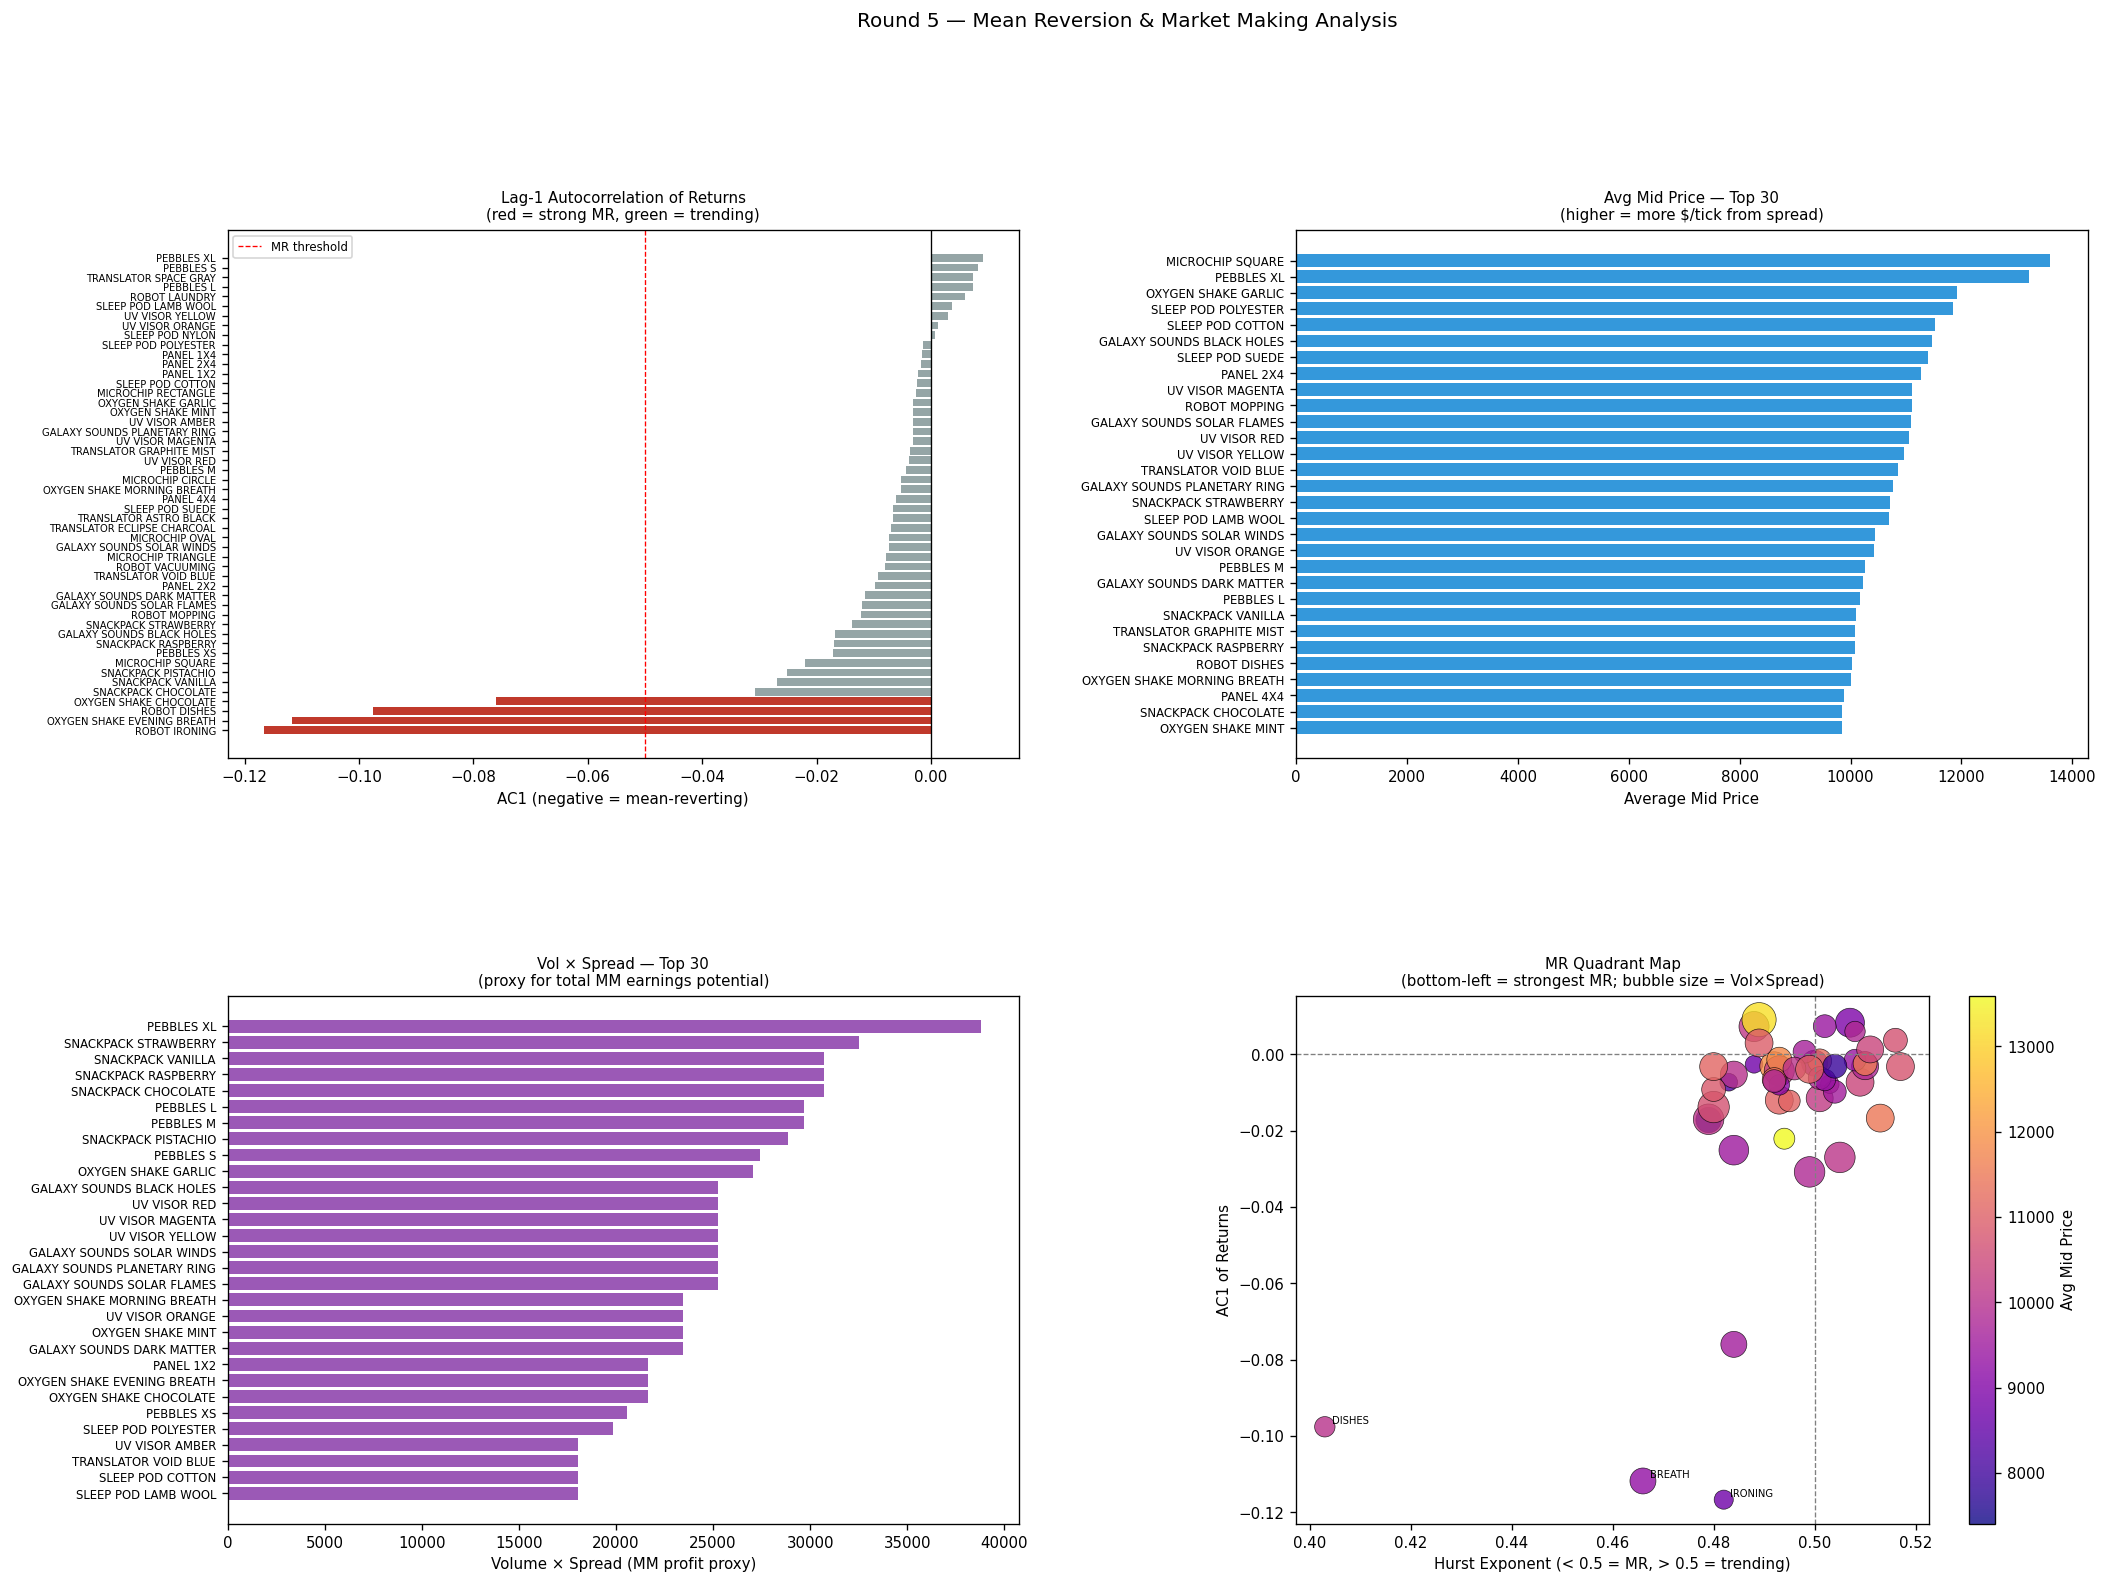

In [8]:
fig = plt.figure(figsize=(20, 14))
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)

# ── Plot 1: AC1 ranked bar ──────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
sdf = stats_df.sort_values('ac1')
colors = ['#c0392b' if v < -0.05 else ('#2ecc71' if v > 0.03 else '#95a5a6') for v in sdf['ac1']]
ax1.barh(range(len(sdf)), sdf['ac1'].values, color=colors)
ax1.set_yticks(range(len(sdf)))
ax1.set_yticklabels([p.replace('_', ' ')[:28] for p in sdf['product']], fontsize=6)
ax1.axvline(0, color='k', lw=0.8)
ax1.axvline(-0.05, color='r', lw=0.8, ls='--', label='MR threshold')
ax1.set_xlabel('AC1 (negative = mean-reverting)')
ax1.set_title('Lag-1 Autocorrelation of Returns\n(red = strong MR, green = trending)', fontsize=9)
ax1.legend(fontsize=7)

# ── Plot 2: Avg mid price ranked ────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
sdf2 = stats_df.sort_values('avg_mid', ascending=False).head(30)
ax2.barh(range(len(sdf2)), sdf2['avg_mid'].values, color='#3498db')
ax2.set_yticks(range(len(sdf2)))
ax2.set_yticklabels([p.replace('_', ' ')[:28] for p in sdf2['product']], fontsize=7)
ax2.set_xlabel('Average Mid Price')
ax2.set_title('Avg Mid Price — Top 30\n(higher = more $/tick from spread)', fontsize=9)
ax2.invert_yaxis()

# ── Plot 3: Vol × Spread ranked ─────────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
sdf3 = stats_df.sort_values('vol_x_spread', ascending=False).head(30)
ax3.barh(range(len(sdf3)), sdf3['vol_x_spread'].values, color='#9b59b6')
ax3.set_yticks(range(len(sdf3)))
ax3.set_yticklabels([p.replace('_', ' ')[:28] for p in sdf3['product']], fontsize=7)
ax3.set_xlabel('Volume × Spread (MM profit proxy)')
ax3.set_title('Vol × Spread — Top 30\n(proxy for total MM earnings potential)', fontsize=9)
ax3.invert_yaxis()

# ── Plot 4: Scatter — AC1 vs Hurst (MR quadrant) ───────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
s4 = stats_df.dropna(subset=['ac1','hurst'])
sc = ax4.scatter(s4['hurst'], s4['ac1'],
                 s=s4['vol_x_spread'] / s4['vol_x_spread'].max() * 400 + 20,
                 c=s4['avg_mid'], cmap='plasma', alpha=0.8, edgecolors='k', lw=0.4)
plt.colorbar(sc, ax=ax4, label='Avg Mid Price')
ax4.axvline(0.5, color='gray', lw=0.8, ls='--')
ax4.axhline(0, color='gray', lw=0.8, ls='--')
ax4.set_xlabel('Hurst Exponent (< 0.5 = MR, > 0.5 = trending)')
ax4.set_ylabel('AC1 of Returns')
ax4.set_title('MR Quadrant Map\n(bottom-left = strongest MR; bubble size = Vol×Spread)', fontsize=9)
# Label strong MR / strong trend
for _, row in s4[s4['ac1'] < -0.08].iterrows():
    ax4.annotate(row['product'].split('_')[-1], (row['hurst'], row['ac1']), fontsize=6,
                 xytext=(4,2), textcoords='offset points')
for _, row in s4[(s4['ac1'] > 0.04) | (s4['hurst'] > 0.55)].iterrows():
    ax4.annotate(row['product'].split('_')[-1], (row['hurst'], row['ac1']), fontsize=6,
                 color='darkgreen', xytext=(4,2), textcoords='offset points')

plt.suptitle('Round 5 — Mean Reversion & Market Making Analysis', fontsize=12, y=1.01)
plt.savefig('mr_ranking.png', bbox_inches='tight', dpi=130)
plt.show()

## 8 — Price Paths for Top MR Candidates

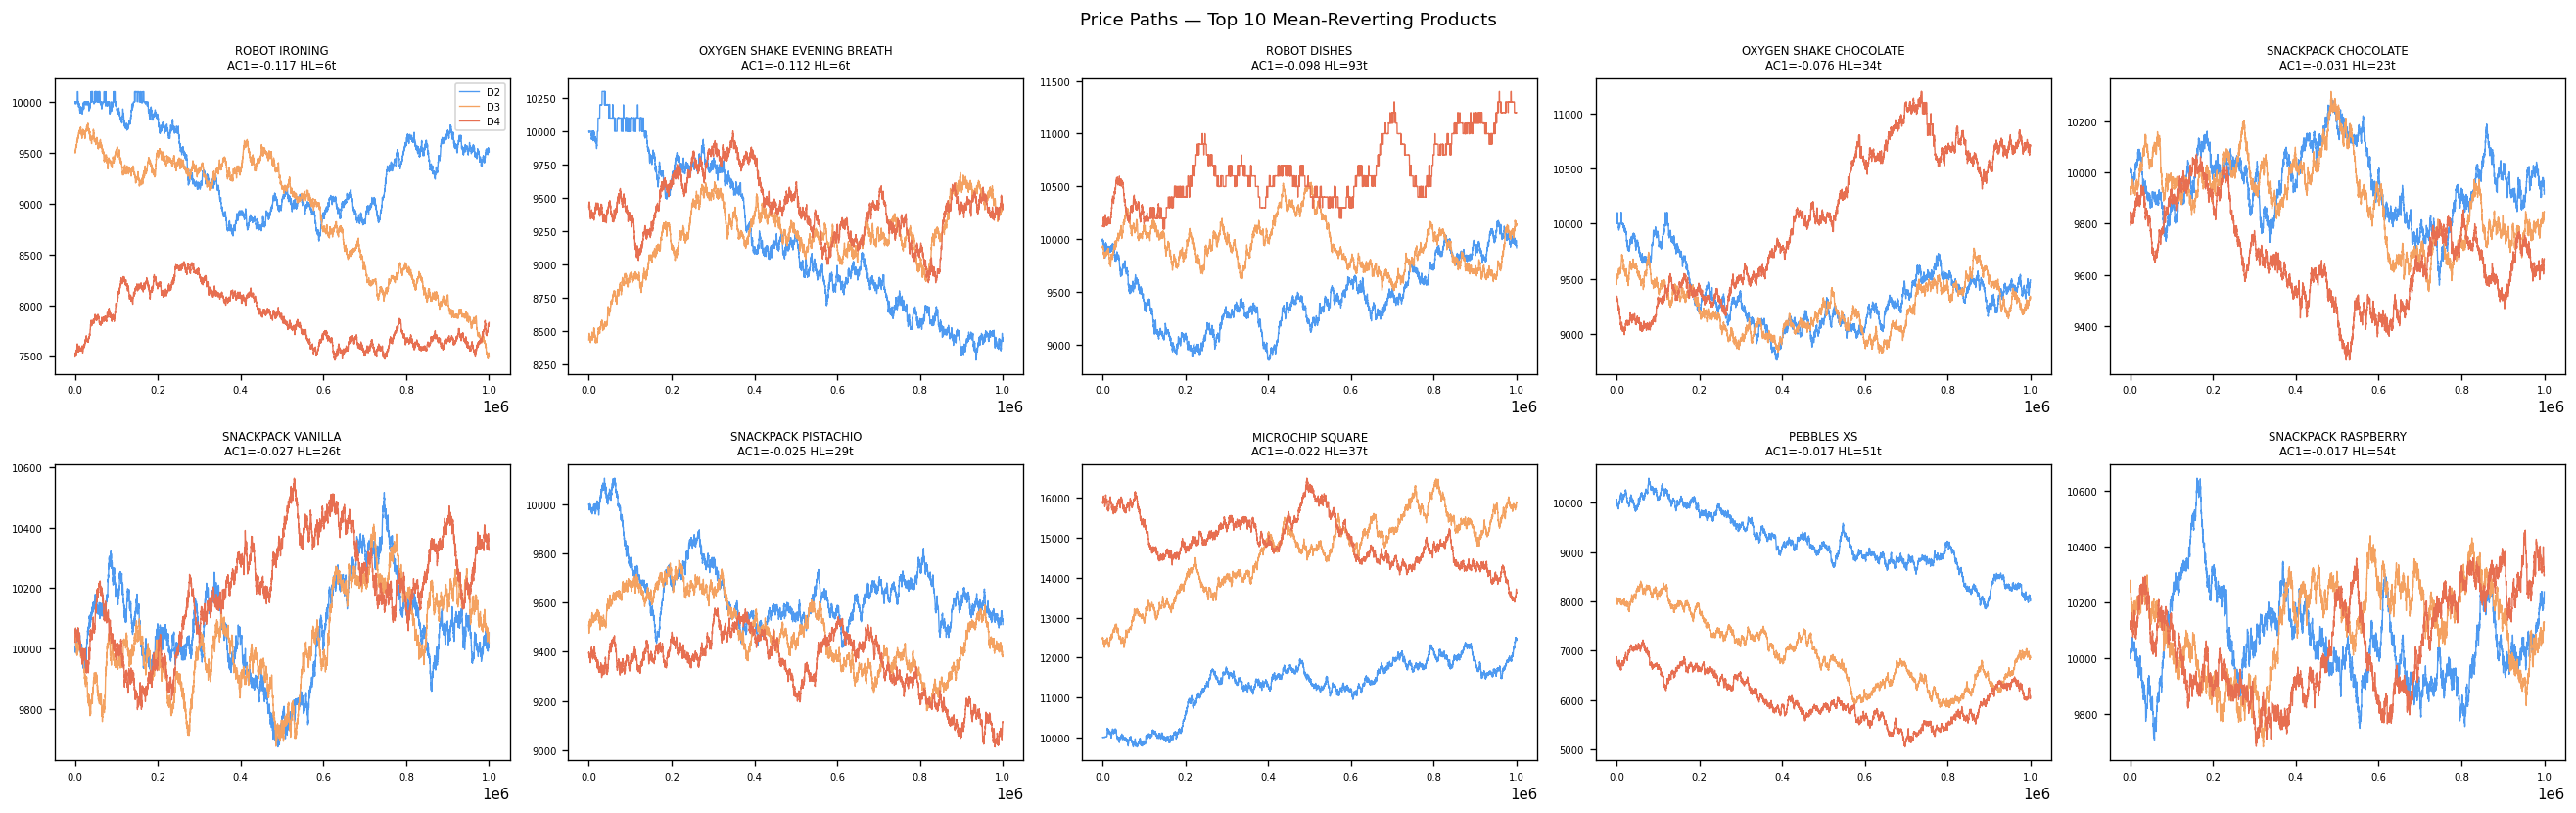

In [9]:
top_mr = stats_df.sort_values('ac1').head(10)['product'].tolist()
fig, axes = plt.subplots(2, 5, figsize=(22, 7), sharey=False)
day_colors = {2: '#4e9af1', 3: '#f4a261', 4: '#e76f51'}

for ax, sym in zip(axes.flat, top_mr):
    sub = prices[prices['product'] == sym]
    for d, dc in day_colors.items():
        ds = sub[sub['day'] == d].sort_values('timestamp')
        ax.plot(ds['timestamp'].values, ds['mid_price'].values, lw=0.8, color=dc, label=f'D{d}')
    r = stats_df[stats_df['product'] == sym].iloc[0]
    ax.set_title(f"{sym.replace('_',' ')}\nAC1={r['ac1']:.3f} HL={r['half_life']:.0f}t", fontsize=7)
    ax.tick_params(labelsize=6)

axes[0,0].legend(fontsize=6)
plt.suptitle('Price Paths — Top 10 Mean-Reverting Products', fontsize=11)
plt.tight_layout()
plt.show()

## 9 — Pebbles Pair Spread Plots

/opt/anaconda3/lib/python3.12/site-packages/numpy/lib/function_base.py:2742: RuntimeWarning: invalid value encountered in subtract
  X -= avg[:, None]
/opt/anaconda3/lib/python3.12/site-packages/numpy/core/_methods.py:118: RuntimeWarning: invalid value encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


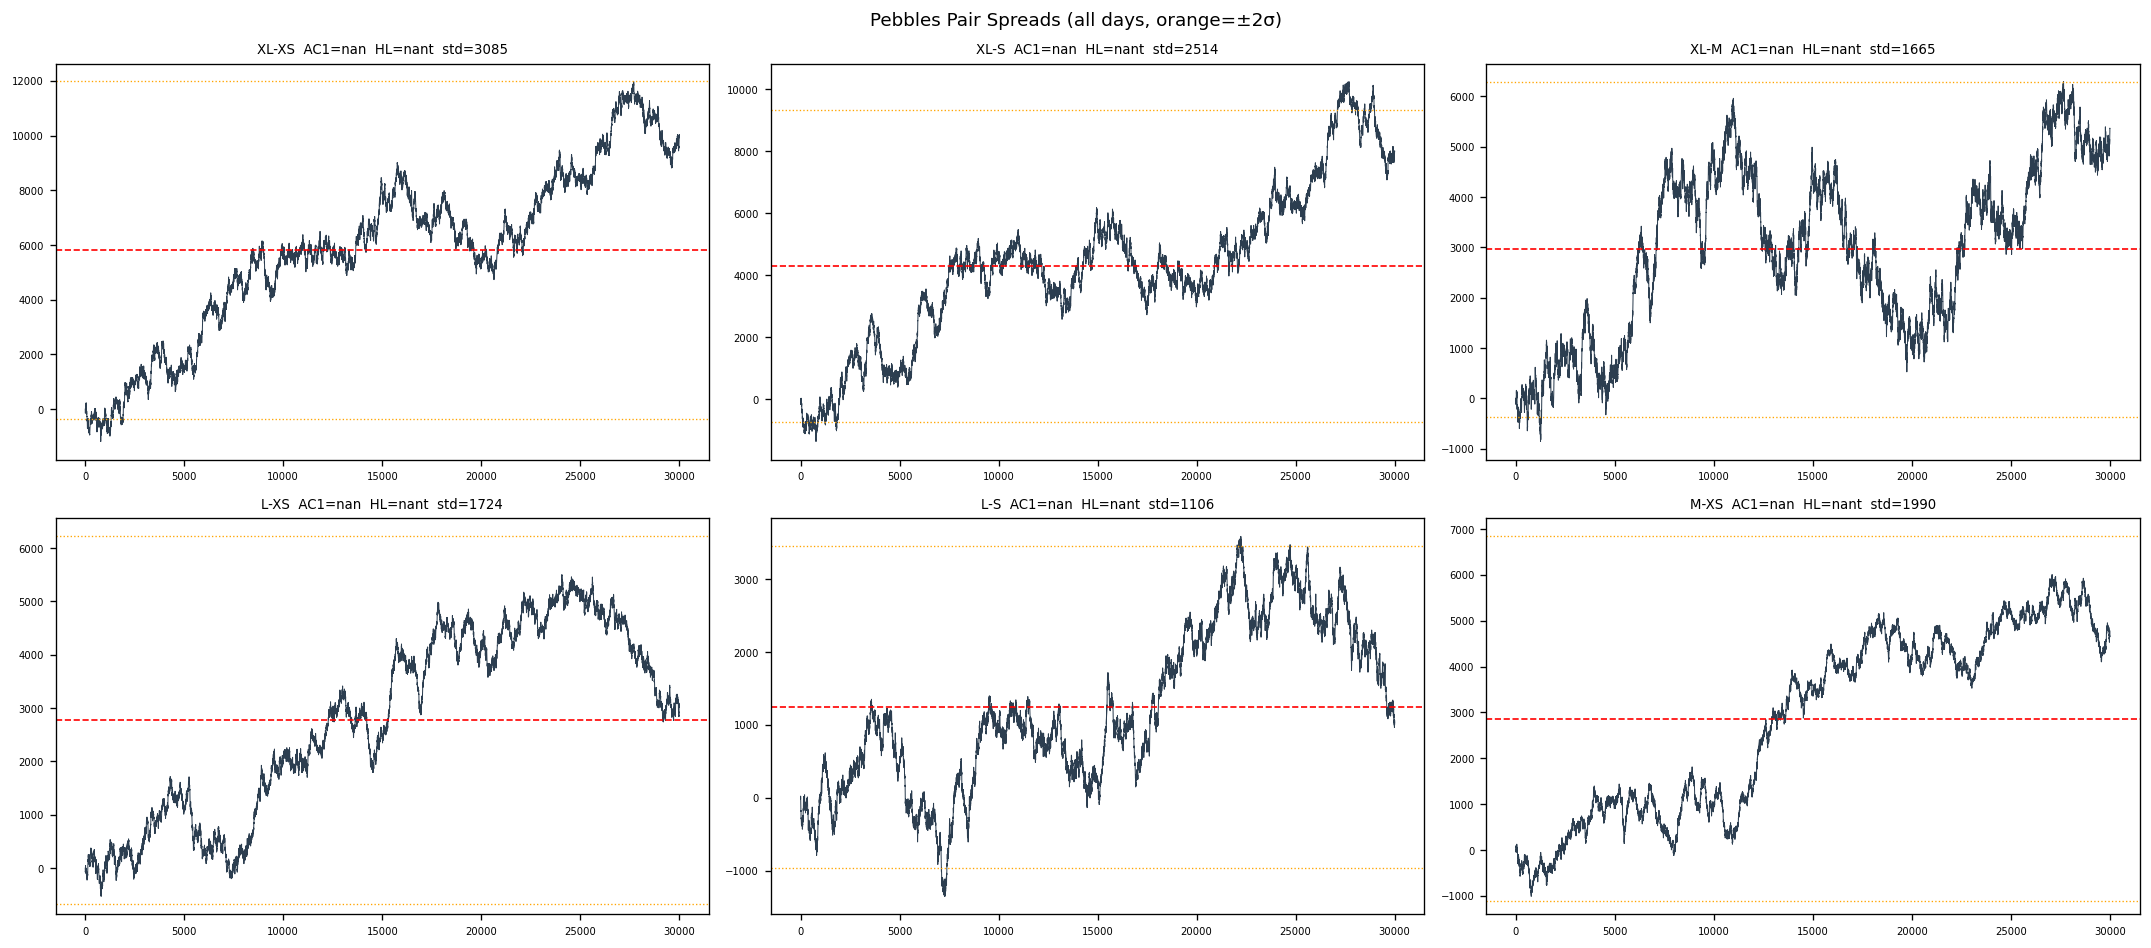

In [10]:
peb_pairs = [('PEBBLES_XL','PEBBLES_XS'), ('PEBBLES_XL','PEBBLES_S'),
             ('PEBBLES_XL','PEBBLES_M'),  ('PEBBLES_L','PEBBLES_XS'),
             ('PEBBLES_L','PEBBLES_S'),   ('PEBBLES_M','PEBBLES_XS')]

sub = prices[prices['product'].isin([p for pair in peb_pairs for p in pair])]
piv = sub.pivot_table(index=['day','timestamp'], columns='product', values='mid_price')

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, (a, b) in zip(axes.flat, peb_pairs):
    sp = piv[a] - piv[b]
    sp = sp.dropna().reset_index(drop=True)
    z  = (sp - sp.mean()) / sp.std()
    a1 = ac1(sp)
    hl = half_life(sp)
    ax.plot(sp.values, lw=0.6, color='#2c3e50')
    ax.axhline(sp.mean(), color='r', lw=1, ls='--')
    ax.axhline(sp.mean() + 2*sp.std(), color='orange', lw=0.8, ls=':')
    ax.axhline(sp.mean() - 2*sp.std(), color='orange', lw=0.8, ls=':')
    na = a.split('_')[1]; nb = b.split('_')[1]
    ax.set_title(f'{na}-{nb}  AC1={a1:.3f}  HL={hl:.1f}t  std={sp.std():.0f}', fontsize=8)
    ax.tick_params(labelsize=6)

plt.suptitle('Pebbles Pair Spreads (all days, orange=±2σ)', fontsize=11)
plt.tight_layout()
plt.show()

## 10 — Summary: Strategy Recommendations

In [11]:
print('=== SUMMARY ===')
print()
print('MR CANDIDATES (AC1 < -0.05, consider skewing quotes or trading residuals):')
mr_strong = stats_df[stats_df['ac1'] < -0.05].sort_values('ac1')
for _, r in mr_strong.iterrows():
    print(f"  {r['product']:40s} AC1={r['ac1']:+.4f}  HL={r['half_life']:5.1f}t  "
          f"spread={r['spread']:4.1f}  vol={r['volume']:4d}  V*S={r['vol_x_spread']:8.0f}")

print()
print('BEST MM TARGETS (high vol_x_spread AND AC1 close to 0):')
mm = stats_df[(stats_df['ac1'].abs() < 0.04) & (stats_df['vol_x_spread'] > 0)].sort_values('vol_x_spread', ascending=False).head(15)
for _, r in mm.iterrows():
    print(f"  {r['product']:40s} avg_mid={r['avg_mid']:8.1f}  spread={r['spread']:4.1f}  "
          f"vol={r['volume']:4d}  V*S={r['vol_x_spread']:8.0f}  AC1={r['ac1']:+.4f}")

print()
print('TRENDING PRODUCTS (Hurst > 0.5 or AC1 > 0.03, hold not MM):')
tr = stats_df[(stats_df['hurst'] > 0.50) | (stats_df['ac1'] > 0.03)].sort_values('hurst', ascending=False)
for _, r in tr.iterrows():
    print(f"  {r['product']:40s} hurst={r['hurst']:.3f}  AC1={r['ac1']:+.4f}")

=== SUMMARY ===

MR CANDIDATES (AC1 < -0.05, consider skewing quotes or trading residuals):
  ROBOT_IRONING                            AC1=-0.1167  HL=  6.0t  spread= 6.0  vol=1805  V*S=   10830
  OXYGEN_SHAKE_EVENING_BREATH              AC1=-0.1118  HL=  6.5t  spread=12.0  vol=1805  V*S=   21660
  ROBOT_DISHES                             AC1=-0.0976  HL= 92.6t  spread= 7.0  vol=1805  V*S=   12635
  OXYGEN_SHAKE_CHOCOLATE                   AC1=-0.0760  HL= 33.5t  spread=12.0  vol=1805  V*S=   21660

BEST MM TARGETS (high vol_x_spread AND AC1 close to 0):
  PEBBLES_XL                               avg_mid= 13225.6  spread=17.0  vol=2283  V*S=   38811  AC1=+0.0091
  SNACKPACK_STRAWBERRY                     avg_mid= 10706.6  spread=18.0  vol=1805  V*S=   32490  AC1=-0.0138
  SNACKPACK_VANILLA                        avg_mid= 10097.3  spread=17.0  vol=1805  V*S=   30685  AC1=-0.0270
  SNACKPACK_RASPBERRY                      avg_mid= 10077.8  spread=17.0  vol=1805  V*S=   30685  AC1=-0.0170